# Assignment: Data Wrangling

### Reading material: `tidy_data.pdf`

**Q1.** This question provides some practice cleaning variables which have common problems.
1. For `./data/airbnb_hw.csv`, clean the `Price` variable as well as you can, and explain the choices you make. How many missing values do you end up with? (Hint: What happens to the formatting when a price goes over 999 dollars, say from 675 to 1,112?)
2. For the Minnesota police use of for data, `./data/mn_police_use_of_force.csv`, clean the `subject_injury` variable, handling the NA's; this gives a value `Yes` when a person was injured by police, and `No` when no injury occurred. What proportion of the values are missing? Is this a concern? Cross-tabulate your cleaned `subject_injury` variable with the `force_type` variable. Are there any patterns regarding when the data are missing?

**Q2.** Go to https://sharkattackfile.net/ and download their dataset on shark attacks (Hint: GSAF5.xls).

Open the shark attack file using Pandas. It is probably not a csv file, so read_csv won't work.
Drop any columns that do not contain data.
Clean the year variable. Describe the range of values you see. Filter the rows to focus on attacks since 1940. Are attacks increasing, decreasing, or remaining constant over time?
Clean the Age variable and make a histogram of the ages of the victims.
What proportion of victims are male?
Clean the Type variable so it only takes three values: Provoked and Unprovoked and Unknown. What proportion of attacks are unprovoked?

---

## *Phase 1: Solution without AI

Complete all questions in the following cells without generative AI. Then commit and push the
notebook before beginning Phase 2.

**Declaration:** I completed this version without generative AI.

**Student:** Evie McMahan

**Date:** 9/2/2026

### **Q1, Part 1:**

In [518]:
import numpy as np
import pandas as pd

df = pd.read_csv('data/airbnb_hw.csv')

# First look at the dataset
print('Loaded from: src/data/airbnb_hw.csv')
print('Rows, columns:', df.shape)
df.head()

Loaded from: src/data/airbnb_hw.csv
Rows, columns: (30478, 13)


,Host Id,Host Since,Name,Neighbourhood,Property Type,Review Scores Rating (bin),Room Type,Zipcode,Beds,Number of Records,Number Of Reviews,Price,Review Scores Rating
0,5162530,NaN,1 Bedroom in Prime Williamsburg,Brooklyn,Apartment,NaN,Entire home/apt,11249.0,1.0,1,0,145,NaN
1,33134899,NaN,"Sunny, Private room in Bushwick",Brooklyn,Apartment,NaN,Private room,11206.0,1.0,1,1,37,NaN
2,39608626,NaN,Sunny Room in Harlem,Manhattan,Apartment,NaN,Private room,10032.0,1.0,1,1,28,NaN
3,500,6/26/2008,Gorgeous 1 BR with Private Balcony,Manhattan,Apartment,NaN,Entire home/apt,10024.0,3.0,1,0,199,NaN
4,500,6/26/2008,Trendy Times Square Loft,Manhattan,Apartment,95.0,Private room,10036.0,3.0,1,39,549,96.0


At first glance, this dataset looks at the properties of different airbnbs in New York. The dataset has 30,478 rows and 13 columns.  

In [519]:
print(df['Price'].describe()) # Initial price description
df['Price'].unique()


count     30478
unique      511
top         150
freq       1481
Name: Price, dtype: object


<StringArray>
[  '145',    '37',    '28',   '199',   '549',   '149',   '250',    '90',
   '270',   '290',
 ...
 '3,100', '2,486', '3,390', '1,356', '2,599',   '472',   '454',   '328',
   '396',   '291']
Length: 511, dtype: str

The first thing I noticed was that `Price` is an object type.

count    30297.000000
mean       153.357032
std        108.895698
min         10.000000
25%         80.000000
50%        125.000000
75%        192.000000
max        999.000000
Name: Price_cleaned, dtype: float64 

[145.  37.  28. 199. 549. 149. 250.  90. 270. 290. 170.  59.  49.  68.
 285.  75. 100. 150. 700. 125. 175.  40.  89.  95.  99. 499. 120.  79.
 110. 180. 143. 230. 350. 135.  85.  60.  70.  55.  44. 200. 165. 115.
  74.  84. 129.  50. 185.  80. 190. 140.  45.  65. 225. 600. 109.  nan
  73. 240.  72. 105. 155. 160.  42. 132. 117. 295. 280. 159. 107.  69.
 239. 220. 399. 130. 375. 585. 275. 139. 260.  35. 133. 300. 289. 179.
  98. 195.  29.  27.  39. 249. 192. 142. 169. 131. 138. 113. 122. 329.
 101. 475. 238. 272. 308. 126. 235. 315. 248. 128.  56. 207. 450. 215.
 210. 385. 445. 136. 247. 118.  77.  76.  92. 198. 205. 299. 222. 245.
 104. 153. 349. 114. 320. 292. 226. 420. 500. 325. 307.  78. 265. 108.
 123. 189.  32.  58.  86. 219. 800. 335.  63. 229. 425.  67.  87. 158.
 650.

<Axes: >

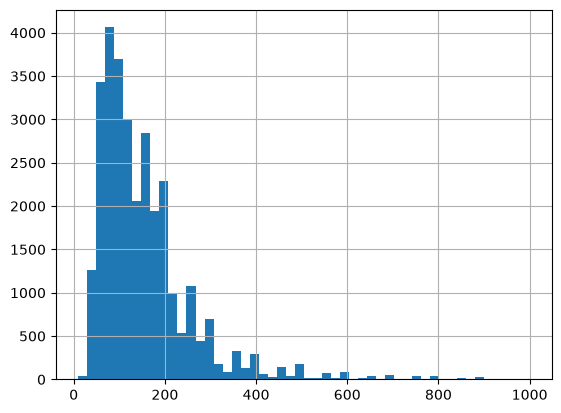

In [520]:
df['Price_cleaned'] = pd.to_numeric(df['Price'], errors='coerce') # Convert Price to numeric
print(df['Price_cleaned'].describe(), '\n') # Post-numeric conversion description
print(df['Price_cleaned'].unique(), '\n')
print(df['Price_cleaned'].value_counts(), '\n')
df['Price_cleaned'].hist(bins = 50) # Show distribution of variable

 After I converted `Price` to numeric, I looked at the unique values, value counts, and distribution to further diagnose the variable. I noticed that the price count was lower (30,297) than before I converted it to a numeric data type (30,478). None of the values over 1,000 show up in the `.unique` analysis, so those values must have gone missing when I converted the variable to numeric.

In [521]:
df['Price_nan'] = df['Price_cleaned'].isnull() # Create new column for missing data
print('Total missing values:', sum(df['Price_nan'])) # Count missing values

df['Price_cleaned'] = df['Price'].str.replace(",","").astype(float) # Remove the commas
df['Price_cleaned'] = pd.to_numeric(df['Price_cleaned'], errors='coerce') # Now, convert the Price without commas to numeric

print('Total missing values after removing commas:', sum(df['Price_cleaned'].isnull()))

Total missing values: 181
Total missing values after removing commas: 0


Great! The commas were the issue that created missing values. I will look one more time at the variable.

In [522]:
print(df['Price_cleaned'].head(), '\n')
print(df['Price_cleaned'].describe(), '\n')
print(df['Price_cleaned'].value_counts())

0    145.0
1     37.0
2     28.0
3    199.0
4    549.0
Name: Price_cleaned, dtype: float64 

count    30478.000000
mean       163.589737
std        197.785454
min         10.000000
25%         80.000000
50%        125.000000
75%        195.000000
max      10000.000000
Name: Price_cleaned, dtype: float64 

Price_cleaned
150.0    1481
100.0    1207
200.0    1059
125.0     889
75.0      873
         ... 
472.0       1
454.0       1
328.0       1
396.0       1
291.0       1
Name: count, Length: 511, dtype: int64


My `Price_cleaned` variable looks clean. It's a numeric type, and there are no missing values. $150 is the most frequent price.

### **Q1, Part 2:**

In [523]:
df = pd.read_csv('data/mn_police_use_of_force.csv')

# First look at the dataset
print('Loaded from: src/data/mn_police_use_of_force.csv')
print('Rows, columns:', df.shape)
df.head()

Loaded from: src/data/mn_police_use_of_force.csv
Rows, columns: (12925, 13)


,response_datetime,problem,is_911_call,primary_offense,subject_injury,force_type,force_type_action,race,sex,age,type_resistance,precinct,neighborhood
0,2016/01/01 00:47:36,Assault in Progress,Yes,DASLT1,NaN,Bodily Force,Body Weight to Pin,Black,Male,20.0,Tensed,1,Downtown East
1,2016/01/01 02:19:34,Fight,No,DISCON,NaN,Chemical Irritant,Personal Mace,Black,Female,27.0,Verbal Non-Compliance,1,Downtown West
2,2016/01/01 02:19:34,Fight,No,DISCON,NaN,Chemical Irritant,Personal Mace,White,Female,23.0,Verbal Non-Compliance,1,Downtown West
3,2016/01/01 02:28:48,Fight,No,PRIORI,NaN,Chemical Irritant,Crowd Control Mace,Black,Male,20.0,Commission of Crime,1,Downtown West
4,2016/01/01 02:28:48,Fight,No,PRIORI,NaN,Chemical Irritant,Crowd Control Mace,Black,Male,20.0,Commission of Crime,1,Downtown West


This is a dataset that describes the instances when police used force. The dataset has 12,925 rows and 13 columns. I already see a lot of NaN's in the `subject_injury` column. 

In [524]:
print(df['subject_injury'].describe(), '\n') # Initial subject_injury description
print(df['subject_injury'].unique(), '\n')
print(df['subject_injury'].value_counts(), '\n')

df['subject_injury_nan'] = df['subject_injury'].isnull() # Create new column for missing data
missing_values_sum = sum(df['subject_injury_nan']) # Sum missing values
proportion_missing = missing_values_sum/(missing_values_sum + df['subject_injury'].count()) # Calculate proportion of missing values

print('Total missing values:', missing_values_sum)
print('Proportion of values missing:', round(proportion_missing*100,2), "%")


count     3077
unique       2
top        Yes
freq      1631
Name: subject_injury, dtype: object 

<StringArray>
[nan, 'No', 'Yes']
Length: 3, dtype: str 

subject_injury
Yes    1631
No     1446
Name: count, dtype: int64 

Total missing values: 9848
Proportion of values missing: 76.19 %


Inspecting `subject_injury`, 76% of values are missing. This is a large proportion of missing values, and it concerns me about the quality of this variable. Other than the nan's, "No" and "Yes" are the only other values, so no string cleaning is needed. I will inspect the patterns in the missing values.

In [525]:
df['subject_injury_cleaned'] = df['subject_injury'].replace(np.nan, 'Missing') # Add missing values so they can be captured in cross tabulation
pd.crosstab(df['subject_injury_cleaned'], df['force_type'], margins = True) # Cross tabulate my cleaned variable with force_type

force_type,Baton,Bodily Force,Chemical Irritant,Firearm,Gun Point Display,Improvised Weapon,Less Lethal,Less Lethal Projectile,Maximal Restraint Technique,Police K9 Bite,Taser,All
subject_injury_cleaned,,,,,,,,,,,,
Missing,2,7051,1421,0,27,74,87,0,170,31,985,9848
No,0,1093,131,2,33,34,0,1,0,2,150,1446
Yes,2,1286,41,0,44,40,0,2,0,44,172,1631
All,4,9430,1593,2,104,148,87,3,170,77,1307,12925


Based on the cross tabulation, the proportion of values that are missing does not appear to be similar across different types of force. Instead, the proportion of missing values by force type is very variable. For example, firearms and less lethal projectiles have no missing values (0 out of 2 and 0 out of 3 missing, respectively), while less lethal and maximal restraint technique only have missing values (87 out of 87 and 170 out of 170 missing, respecively). This supports the hypothesis that the missingness of `subject_injury` differs based on `force_type`. This makes the 76% of values missing even more concerning since the proportion isn't spread evenly across `force_type`, and thus may be biased.

### **Q2:**

In [526]:
df = pd.read_excel('data/GSAF5.xls') 

# First look at the dataset
print('Loaded from: src/data/GSAF5.csv')
print('Rows, columns:', df.shape)
df.head()

Loaded from: src/data/GSAF5.csv
Rows, columns: (7117, 23)


,Date,Year,Type,Country,State,Location,Activity,Name,Sex,Age,...,Species,Source,pdf,href formula,href,Case Number,Case Number.1,original order,Unnamed: 21,Unnamed: 22
0,26th August,2026.0,Unprovoked,USA,Hawaii,"Ala Moana Beach Park, Oah'u",Surfing,Unknown Female,F,?,...,Tiger Shark,Keith Cowley: KHON: KITV:,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,23rd August,2026.0,Unprovoked,USA,Florida,Boca Grande (island in the keys),Wading on a sandbar,David Daniel,M,43,...,Large shark,Keith Cowley: Todd Smith: NBC 6: ABC News:,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,19th August,2026.0,Provoked,Reunion Island,Saint-Gilles-les-Baines,Outer Reef Roches Noires,Spearfishiong,Male,M,?,...,Bull shark 2.5m (8.2 ft),Todd Smith: Local Report Zinfos 874:,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,11th August,2026.0,Provoked,Ireland,Waterford,Ardemore County,Fishing,Sebastian Achim,M,27,...,1.5m (5ft) Blue shark,Keith Cowley: David Bargh: Irish Times BBC Met...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,8th August,2026.0,Unprovoked,USA,Maine,Scarborough Beach Park,Operation of Rescue Torpedo,Greg Wilfert,M,71,...,Great White Shark,WGME: CBS News: Keith Cowley,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


After opening the shark attack incidence log, I noticed many issues with the dataset. For example, there are unnamed columns (i.e. `Unnamed: 21`), many columns have only NaN's in the first 5 observations, and `age` has question mark values. I will start by inspecting which columns have no data at all.

In [527]:
print(df.notna().sum()) # Print the number of values that aren't NaN in each column

Date              7117
Year              7115
Type              7099
Country           7067
State             6630
Location          6550
Activity          6534
Name              6899
Sex               6539
Age               4123
Injury            7081
Fatal Y/N         6556
Time              3590
Species           3986
Source            7097
pdf               6799
href formula      6794
href              6796
Case Number       6798
Case Number.1     6797
original order    6799
Unnamed: 21          1
Unnamed: 22          2
dtype: int64


The two "unnamed" columns only have 1 to 2 non-NA values, so I am going to inspect them further.

In [528]:
# Inspect the values and their corresponding counts in the "unnamed" columns
print(df['Unnamed: 21'].value_counts(), '\n')
print(df['Unnamed: 22'].value_counts())

df_cleaned = df.drop(columns = ['Unnamed: 21', 'Unnamed: 22']) # Drop the two columns
print(df_cleaned.shape)
df_cleaned.head()

Unnamed: 21
stopped here    1
Name: count, dtype: int64 

Unnamed: 22
Teramo             1
change filename    1
Name: count, dtype: int64
(7117, 21)


,Date,Year,Type,Country,State,Location,Activity,Name,Sex,Age,...,Fatal Y/N,Time,Species,Source,pdf,href formula,href,Case Number,Case Number.1,original order
0,26th August,2026.0,Unprovoked,USA,Hawaii,"Ala Moana Beach Park, Oah'u",Surfing,Unknown Female,F,?,...,N,1330hrs,Tiger Shark,Keith Cowley: KHON: KITV:,NaN,NaN,NaN,NaN,NaN,NaN
1,23rd August,2026.0,Unprovoked,USA,Florida,Boca Grande (island in the keys),Wading on a sandbar,David Daniel,M,43,...,N,1700hrs,Large shark,Keith Cowley: Todd Smith: NBC 6: ABC News:,NaN,NaN,NaN,NaN,NaN,NaN
2,19th August,2026.0,Provoked,Reunion Island,Saint-Gilles-les-Baines,Outer Reef Roches Noires,Spearfishiong,Male,M,?,...,N,?,Bull shark 2.5m (8.2 ft),Todd Smith: Local Report Zinfos 874:,NaN,NaN,NaN,NaN,NaN,NaN
3,11th August,2026.0,Provoked,Ireland,Waterford,Ardemore County,Fishing,Sebastian Achim,M,27,...,N,1615hrs,1.5m (5ft) Blue shark,Keith Cowley: David Bargh: Irish Times BBC Met...,NaN,NaN,NaN,NaN,NaN,NaN
4,8th August,2026.0,Unprovoked,USA,Maine,Scarborough Beach Park,Operation of Rescue Torpedo,Greg Wilfert,M,71,...,N,1300hrs,Great White Shark,WGME: CBS News: Keith Cowley,NaN,NaN,NaN,NaN,NaN,NaN


I dropped `Unnamed: 21` and `Unnamed: 22` because they didn't have meaningful data within them. They both had either 1 or 2 lines of meaningless data that weren't tied to any variables or observations.

In [529]:
print(df_cleaned['Year'].describe(), '\n') # Initial Year description
print(df_cleaned['Year'].unique(), '\n')
print('NaN sum:', sum(df_cleaned['Year'].isna())) # Determine how many NaN values Year has

count    7115.000000
mean     1936.549122
std       269.943193
min         0.000000
25%      1948.000000
50%      1987.000000
75%      2010.000000
max      2026.000000
Name: Year, dtype: float64 

[2026. 2025. 2024. 2023. 2022. 2021. 2020. 2019. 2018. 2017.   nan 2016.
 2015. 2014. 2013. 2012. 2011. 2010. 2009. 2008. 2007. 2006. 2005. 2004.
 2003. 2002. 2001. 2000. 1999. 1998. 1997. 1996. 1995. 1984. 1994. 1993.
 1992. 1991. 1990. 1989. 1969. 1988. 1987. 1986. 1985. 1983. 1982. 1981.
 1980. 1979. 1978. 1977. 1976. 1975. 1974. 1973. 1972. 1971. 1970. 1968.
 1967. 1966. 1965. 1964. 1963. 1962. 1961. 1960. 1959. 1958. 1957. 1956.
 1955. 1954. 1953. 1952. 1951. 1950. 1949. 1948. 1848. 1947. 1946. 1945.
 1944. 1943. 1942. 1941. 1940. 1939. 1938. 1937. 1936. 1935. 1934. 1933.
 1932. 1931. 1930. 1929. 1928. 1927. 1926. 1925. 1924. 1923. 1922. 1921.
 1920. 1919. 1918. 1917. 1916. 1915. 1914. 1913. 1912. 1911. 1910. 1909.
 1908. 1907. 1906. 1905. 1904. 1903. 1902. 1901. 1900. 1899. 1898. 1897.


The range of values in `Year` is from 0 to 2026, with 75% occuring after 1948. There are definitely outliers, especially the values 0, 5, and 77. The instructions say to filter the rows to focus on attacks since 1940. Since there are only two NaN values, I am going to keep them and convert the rest of the Year values to integers.

count         5581.0
mean     1992.668518
std        24.311209
min           1940.0
25%           1970.0
50%           2000.0
75%           2013.0
max           2026.0
Name: Year, dtype: Float64 

Year
1940     24
1941     27
1942     41
1943     28
1944     31
       ... 
2022     98
2023    109
2024     52
2025     69
2026     53
Name: count, Length: 87, dtype: Int64


<Axes: xlabel='Year'>

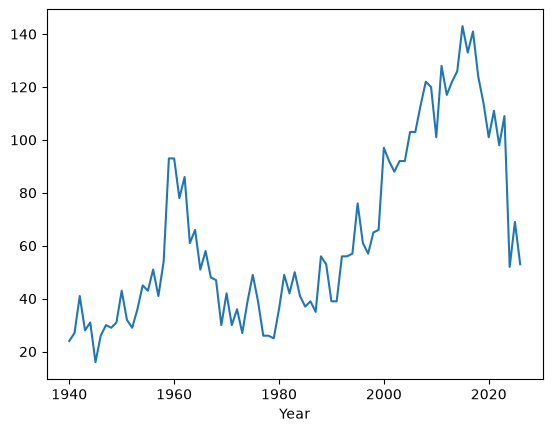

In [530]:
import matplotlib.pyplot as plt

df_cleaned['Year'] = df_cleaned['Year'].astype('Int64') # Remove the decimal place
df_cleaned = df_cleaned.loc[df_cleaned['Year'] >= 1940] # Filter attacks since 1940

print(df_cleaned['Year'].describe(), '\n')
print(df_cleaned['Year'].value_counts().sort_index())

df_counts = df_cleaned['Year'].value_counts().sort_index() # Create variable of value counts by year, sorted
df_counts.plot(kind='line') # Plot a line chart


Attacks in general have increased over time, although not linearly. I plotted a quick line chart to visualize the relationship between year and the number of shark attacks. Attacks per year peaked around 1960 and then again around 2018.

In [531]:
print(df_cleaned['Age'].dtype) # Initial Age description
print(df_cleaned['Age'].describe(), '\n')
print(df_cleaned['Age'].unique())
print(df_cleaned['Age'].value_counts(), '\n')

print('NaN sum:', sum(df_cleaned['Age'].isna())) # Determine how many NaN values Age has
print('Occurances of "or":', df_cleaned['Age'].str.count('or').sum()) # Number of times "or" is in a value in Age
print('Occurances of "and":', df_cleaned['Age'].str.count('and').sum()) 
print('Occurances of "&":', df_cleaned['Age'].str.count('&').sum()) 
print('Occurances of "months":', df_cleaned['Age'].str.count('months').sum()) 




object
count     3804
unique     239
top         16
freq        80
Name: Age, dtype: int64 

['?' '43' '27' '71' '21' '69' '31' '13' '12' '17' '35' "20's" '19' '11'
 '20' '38' '39' '16' '22' '30+' "50's" '55' '26' '56' '24' '25' '61' '40'
 '14' '50+' '54' '48' '57' '8' '63' '9' '7' '85' '18' '66' '37' '42' '45'
 '30' '60' '40+' '29' 35 58 29 24 20 55 17 12 37 36 23 40 28 69 48 '60+'
 57 45 61 27 38 16 68 33 30 15 41 14 43 26 'Middle age' 18 21 49 25 46 19
 65 64 nan '46' '32' '10' '64' '62' '15' '52' '44' '47' '59' '50' '34'
 '30s' '20/30' '65' '20s' '77' '49' '!2' '73' '50s' '58' '67' '6' '41'
 '53' '68' '51' 39 51 10 13 60 '40s' 62 'teen' 8 22 32 56 'Teen' 42 50 'M'
 9 31 11 34 '!6' '!!' 47 7 71 59 53 54 75 '45 and 15' 73 52 70 4 63 44
 '28 & 22' '22, 57, 31' '60s' 67 74 '9 & 60' 'a minor' 6 3 82 '40?' 66 72
 '23' '36' '70' '18 months' '28' '33' '74' '3' '28 & 26' '5' '86'
 '18 or 20' '12 or 13' '46 & 34' '28, 23 & 30' 'Teens' 77 '36 & 26'
 '8 or 10' 84 '\xa0 ' ' ' '30 or 36' '6½' '2

I need to convert `Age` to a numeric variable, but first I have to decide what to do with the messy values. There are many problems here. Some values have multiple ages, some just have age descriptions, and others are completely unknown. I sorted through the column to determine how many instances of "or", "and", "&", and "months" there are. Since there are only 47 combined values with a variation of these words, I will coerce every messy value to be NaN. Question marks and age descriptions (such as elderly) should also become NaN.

count    3645.000000
mean       28.638409
std        14.843747
min         1.000000
25%        17.000000
50%        25.000000
75%        38.000000
max        87.000000
Name: Age, dtype: float64 

[nan 43. 27. 71. 21. 69. 31. 13. 12. 17. 35. 19. 11. 20. 38. 39. 16. 22.
 55. 26. 56. 24. 25. 61. 40. 14. 54. 48. 57.  8. 63.  9.  7. 85. 18. 66.
 37. 42. 45. 30. 60. 29. 58. 36. 23. 28. 68. 33. 15. 41. 49. 46. 65. 64.
 32. 10. 62. 52. 44. 47. 59. 50. 34. 77. 73. 67.  6. 53. 51. 75. 70.  4.
 74.  3. 82. 72.  5. 86. 84. 87.  1. 81. 78.]
Age
17.0    151
20.0    141
15.0    141
19.0    137
18.0    137
       ... 
84.0      1
87.0      1
1.0       1
81.0      1
78.0      1
Name: count, Length: 82, dtype: int64 



<Axes: >

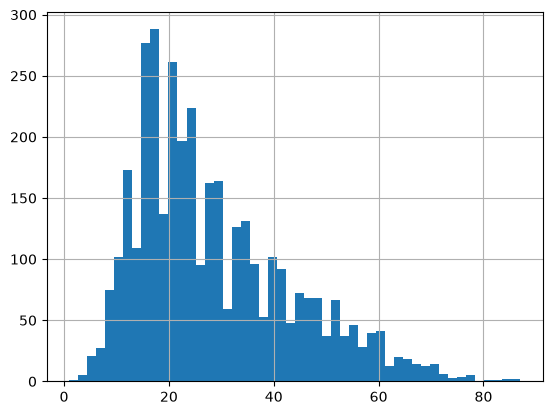

In [532]:
df_cleaned['Age'] = pd.to_numeric(df_cleaned['Age'], errors='coerce') # Convert the object type to numeric, make all messy data NaN
df_cleaned['Age_NaN'] = df_cleaned['Age'].isnull() # Preserve countable record of null values

print(df_cleaned['Age'].describe(), '\n')
print(df_cleaned['Age'].unique())
print(df_cleaned['Age'].value_counts(), '\n')
df_cleaned['Age'].hist(bins = 50) # Create histogram

Now that the `Age` variable is clean, you can see the distribution on the histogram. No age is spared from a shark attack, as ages span from 1 to 87 years old. The most frequent age to be attacked by a shark is 17, and then the value count declines as you age.

In [533]:
print(df_cleaned['Sex'].describe(), '\n') # Initial Sex description
print(df_cleaned['Sex'].unique(), '\n')
print(df_cleaned['Sex'].value_counts(), '\n')
print('NaN sum:', sum(df_cleaned['Sex'].isna())) # Determine how many NaN values Sex has

count     5130
unique      10
top          M
freq      4384
Name: Sex, dtype: object 

<StringArray>
['F', 'M', 'M ', 'M F', '?', 'F ', nan, ' M', 'm', 'lli', 'M x 2']
Length: 11, dtype: str 

Sex
M        4384
F         730
M           7
?           2
F           2
M F         1
 M          1
m           1
lli         1
M x 2       1
Name: count, dtype: int64 

NaN sum: 451


I will drop the rows with multiple victims, such as "M F" and "M x 2", to be consist with how I treated `Age` (made them NaN). I will also make "?", and "lli" values NaN. I will clean the other male values to have no spaces before/after and follow the same capitalization as "M".

In [534]:
df_cleaned['Sex'] = df_cleaned['Sex'].replace(['M F', 'lli', 'M x 2', '?'], np.nan) # Replace messy values with NaN
df_cleaned['Sex'] = df_cleaned['Sex'].str.strip() # Remove extra spaces around Sex values
df_cleaned['Sex'] = df_cleaned['Sex'].str.upper() # Make Sex values uppercase

print(df_cleaned['Sex'].value_counts(), '\n')
print('Proportion of male victims:', round(df_cleaned['Sex'].value_counts(normalize=True)['M']*100,2), "%") # Calculate the relative frequency of the "M" value 


Sex
M    4393
F     732
Name: count, dtype: int64 

Proportion of male victims: 85.72 %


After my cleaning, I found the proportion of male victims to be about 85%. That is a super interesting finding. 

In [535]:
print(df_cleaned['Type'].describe(), '\n') # Initial Type description
print(df_cleaned['Type'].unique(), '\n')
print(df_cleaned['Type'].value_counts(), '\n')
print('NaN sum:', sum(df_cleaned['Type'].isna())) # Determine how many NaN values Type has

count           5567
unique            14
top       Unprovoked
freq            4161
Name: Type, dtype: object 

<StringArray>
[         'Unprovoked',            'Provoked',        'Questionable',
          'UNprovoked',          'unprovoked',           ' Provoked',
          'Watercraft',        'Sea Disaster',                   nan,
                   '?',         'Unconfirmed',          'Unverified',
             'Invalid', 'Under investigation',                'Boat']
Length: 15, dtype: str 

Type
Unprovoked             4161
Provoked                526
Invalid                 402
Watercraft              280
Sea Disaster            156
Questionable             27
Boat                      7
 Provoked                 2
UNprovoked                1
unprovoked                1
?                         1
Unconfirmed               1
Unverified                1
Under investigation       1
Name: count, dtype: int64 

NaN sum: 14


In order to make all the values fall into Provoked, Unprovoked, and Unknown, I will first remove the extra spaces and capitalize the values. Then I will impute all values other than Provoked and Unprovoked to be Unknown. I didn't make a separate impute variable since df already has been copied via `df_cleaned`.

In [536]:
df_cleaned['Type'] = df_cleaned['Type'].str.strip() # Remove extra spaces
df_cleaned['Type'] = df_cleaned['Type'].str.capitalize() # Make values capitalized

print(df_cleaned['Type'].value_counts(), '\n')

impute_value = 'Unknown'
df_cleaned['Type'] = np.where(df_cleaned['Type'].isin(['Provoked','Unprovoked']), df_cleaned['Type'],impute_value) # For any value that isn't "Provoked" or "Unprovoked", fill in "Unknown"
print(df_cleaned['Type'].value_counts(), '\n')

print('Proportion of unprovoked attacks:', round(df_cleaned['Type'].value_counts(normalize = True)['Unprovoked']*100,2), "%")



Type
Unprovoked             4163
Provoked                528
Invalid                 402
Watercraft              280
Sea disaster            156
Questionable             27
Boat                      7
?                         1
Unconfirmed               1
Unverified                1
Under investigation       1
Name: count, dtype: int64 

Type
Unprovoked    4163
Unknown        890
Provoked       528
Name: count, dtype: int64 

Proportion of unprovoked attacks: 74.59 %


Approximately 75% of attacks are unprovoked.

## *Phase 2: AI-assisted Revision
Keep Phase 1 frozen.

- **Phase 1 commit SHA ID:** 380853e8ced784062f52f9a85cc952891e841ebe
- **AI tool and model used:** Claude Opus 5

### *Prompts used

1. Please audit and propose revisions for A1: Data Wrangling. I have attached our lecture notes for the week, the assignment rubric, and my notebook & data files. I want you to provide me with a list of proposed changes to improve my work and score 100% on the rubric.
2. Please give me a concise list of the top 10 most impactful changes.

### *AI-proposed changes


1. Row-normalized cross-tab (Q1, 2e, 8.75 pts). Add normalize='index' alongside your count table, with n per force type, sorted by missing rate. Your counts are correct but the pattern is nearly unreadable from raw numbers. Biggest single item on the rubric.
2. Report Age missingness after cleaning (Q2, 2.5, 2.6, 11.25 pts). 1,936 of 5,581, or 34.7%. You build Age_NaN and never print it. The histogram means little without this number attached.
3. Fix the Year filter contradiction (Q2, 2.3). Your prose says you keep the two NaN years; >= 1940 silently drops them. This is the clearest place a grader sees code disagreeing with a stated claim.
4. Swap the Age justification (Q2, 2.6). Replace "only 47 messy values" with the real 159, then argue from the recovery test: rescuing them moves the mean from 28.64 to 28.65 and leaves the median at 25, so the simple rule is the right one. Same decision, defensible reasoning.
5. Add Q2 sub-headers (all 11 Q2 items). Eleven separate criteria, one header, continuous prose. Headers matching the question numbers protect every "attempt" point in the section.
6. State the male-proportion denominator (Q2, 2.8, 5 pts). 85.7% of the 5,125 records with recorded sex, or 78.7% of all 5,581 rows. Give both. The distinction is most of what this item tests.
7. Label both plots (Q2, 2.4, 2.7). Titles and axis labels on the year line chart and the age histogram. Also switch bins=50 to bins=range(0, 90, 5), since 50 bins over ages 1 to 87 creates gaps that are pure binning artifact.
8. Correct the peak year and add the reporting caveat (Q2, 2.4). Modern peak is 2015 at 143, not 2018. Then note that 2024 to 2026 look artificially low because GSAF fills in retroactively and 2026 is partial, so the recent decline is not real.
9. Name the missingness mechanism and cut the n=2 evidence (Q1, 2c, 2f). Missingness depends on force_type, so the data are not missing completely at random and dropping NAs erases 100% of Maximal Restraint Technique and Less Lethal incidents. Move your argument off the firearm cell (0 of 2) and onto Chemical Irritant at 89.2% of 1,593.
10. Add the unprovoked sensitivity figure (Q2, 2.10, 2.11). 74.6% of all records versus 88.7% of the 4,691 where provocation is actually known, plus a sentence justifying why Watercraft, Sea Disaster, and Boat (443 records) go into Unknown.
11. If you want an eleventh that costs almost nothing: write "0 missing values out of 30,478" explicitly for the Airbnb answer (Q1, 1c), since that criterion asks for a count and you currently only say there are none.

### *Evaluation of AI suggestions


| Change | Decision | Reason and verification |
|---|---|---|
| 1 | Accept | I accept this change since it will make my cross-tabulation easier to read, but it doesn't have an impact on my analysis or conclusion since I already included the "All" margins to be able to visualize the proportions. I will add this version of the cross-tabulation below my original. I verified the numbers by double checking the proportions based on my original chart.|
| 2 | Accept | I accept this change since the missingness of `Age` is a clear limitation, and printing the total number of missing values helps to clarify the limitations of the histogram. I verified this number by adding the original NaN values to the non-numeric, non-null values that I counted before converting all values to numeric. |
| 3 | Accept | I double checked to see if the NaN values were dropped after filtering `Year` to be >= 1940, and they were dropped. As a result, I edited my markdown comments. |
| 4 | Modify | I changed out my justification to include all non-numeric, non-missing numbers rather than just the keywords that I searched for. I didn't include the recovery test because the proportion of NaN values that could be imputed was so small. |
| 5 | Accept | I might as well add headers to make the code review easier. |
| 6 | Modify | I denoted in my explanation that I found the proportion of values with a recorded sex. I also included the proportion of values with no sex recorded, but I don't believe I need to have multiple proportions in my answer when the question asks for one. |
| 7 | Accept | I will label my plots to make them more clear and provide descriptions. On the histogram, I will adjust the bins to increase readability. I verified this by thinking about how my previous `bins = 50` bucketed the data. It divided roughly 1 to 87 into 50 slices of about 1.7 years each, which is not as clean as having 5 year intervals. |
| 8 | Accept | I was previously estimating the peak year based on the line chart visualization, but I will calculate it and be precise. I verified the calculated number with the graph, and they aligned. I added that 2026 is a partial year for clarification, but I believe that can be assumed. |
| 9 | Modify | I kept the evidence on the `force_type` values that didn't match any missing `subject_injury` values, but I added additional detail on the pattern of missingness data. |
| 10 | Reject | I reject this change because the prompt asks for the proportion of attacks that are unprovoked given the three possible values (Provoked, Unprovoked, and Unknown). Finding the proportion of unprovoked attacks for the values that are known wasn't asked in the prompt, but I will caveat this in my explanation to denote how I calculated the proportion. |
| 11 | Accept | This change makes little impact on my solution, but it is just a more explicit answer to the question. Rather than explaining that there are "no" missing values after my cleaning work, I wrote there were "0 missing values out of 30,478". I referenced `.describe()` to verify the total number of values. |

### *AI-assisted solution in full
After the evaluation of AI suggestions, incorporate the accepted revisions into your Phase 1 solution and provide the final Phase 2 solution in full in the following cells.

### **Q1, Part 1:**

In [537]:
import numpy as np
import pandas as pd

df = pd.read_csv('data/airbnb_hw.csv')

# First look at the dataset
print('Loaded from: src/data/airbnb_hw.csv')
print('Rows, columns:', df.shape)
df.head()

Loaded from: src/data/airbnb_hw.csv
Rows, columns: (30478, 13)


,Host Id,Host Since,Name,Neighbourhood,Property Type,Review Scores Rating (bin),Room Type,Zipcode,Beds,Number of Records,Number Of Reviews,Price,Review Scores Rating
0,5162530,NaN,1 Bedroom in Prime Williamsburg,Brooklyn,Apartment,NaN,Entire home/apt,11249.0,1.0,1,0,145,NaN
1,33134899,NaN,"Sunny, Private room in Bushwick",Brooklyn,Apartment,NaN,Private room,11206.0,1.0,1,1,37,NaN
2,39608626,NaN,Sunny Room in Harlem,Manhattan,Apartment,NaN,Private room,10032.0,1.0,1,1,28,NaN
3,500,6/26/2008,Gorgeous 1 BR with Private Balcony,Manhattan,Apartment,NaN,Entire home/apt,10024.0,3.0,1,0,199,NaN
4,500,6/26/2008,Trendy Times Square Loft,Manhattan,Apartment,95.0,Private room,10036.0,3.0,1,39,549,96.0


At first glance, this dataset looks at the properties of different airbnbs in New York. The dataset has 30,478 rows and 13 columns.  

In [538]:
print(df['Price'].describe()) # Initial price description
df['Price'].unique()


count     30478
unique      511
top         150
freq       1481
Name: Price, dtype: object


<StringArray>
[  '145',    '37',    '28',   '199',   '549',   '149',   '250',    '90',
   '270',   '290',
 ...
 '3,100', '2,486', '3,390', '1,356', '2,599',   '472',   '454',   '328',
   '396',   '291']
Length: 511, dtype: str

The first thing I noticed was that `Price` is an object type.

count    30297.000000
mean       153.357032
std        108.895698
min         10.000000
25%         80.000000
50%        125.000000
75%        192.000000
max        999.000000
Name: Price_cleaned, dtype: float64 

[145.  37.  28. 199. 549. 149. 250.  90. 270. 290. 170.  59.  49.  68.
 285.  75. 100. 150. 700. 125. 175.  40.  89.  95.  99. 499. 120.  79.
 110. 180. 143. 230. 350. 135.  85.  60.  70.  55.  44. 200. 165. 115.
  74.  84. 129.  50. 185.  80. 190. 140.  45.  65. 225. 600. 109.  nan
  73. 240.  72. 105. 155. 160.  42. 132. 117. 295. 280. 159. 107.  69.
 239. 220. 399. 130. 375. 585. 275. 139. 260.  35. 133. 300. 289. 179.
  98. 195.  29.  27.  39. 249. 192. 142. 169. 131. 138. 113. 122. 329.
 101. 475. 238. 272. 308. 126. 235. 315. 248. 128.  56. 207. 450. 215.
 210. 385. 445. 136. 247. 118.  77.  76.  92. 198. 205. 299. 222. 245.
 104. 153. 349. 114. 320. 292. 226. 420. 500. 325. 307.  78. 265. 108.
 123. 189.  32.  58.  86. 219. 800. 335.  63. 229. 425.  67.  87. 158.
 650.

<Axes: >

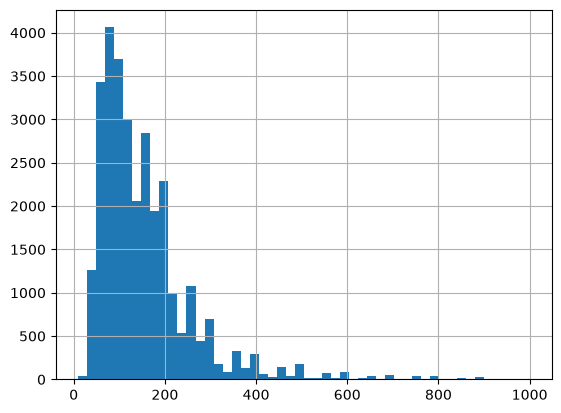

In [539]:
df['Price_cleaned'] = pd.to_numeric(df['Price'], errors='coerce') # Convert Price to numeric
print(df['Price_cleaned'].describe(), '\n') # Post-numeric conversion description
print(df['Price_cleaned'].unique(), '\n')
print(df['Price_cleaned'].value_counts(), '\n')
df['Price_cleaned'].hist(bins = 50) # Show distribution of variable

 After I converted `Price` to numeric, I looked at the unique values, value counts, and distribution to further diagnose the variable. I noticed that the price count was lower (30,297) than before I converted it to a numeric data type (30,478). None of the values over 1,000 show up in the `.unique` analysis, so those values must have gone missing when I converted the variable to numeric.

In [540]:
df['Price_nan'] = df['Price_cleaned'].isnull() # Create new column for missing data
print('Total missing values:', sum(df['Price_nan'])) # Count missing values

df['Price_cleaned'] = df['Price'].str.replace(",","").astype(float) # Remove the commas
df['Price_cleaned'] = pd.to_numeric(df['Price_cleaned'], errors='coerce') # Now, convert the Price without commas to numeric

print('Total missing values after removing commas:', sum(df['Price_cleaned'].isnull()))

Total missing values: 181
Total missing values after removing commas: 0


Great! The commas were the issue that created missing values. I will look one more time at the variable.

In [541]:
print(df['Price_cleaned'].head(), '\n')
print(df['Price_cleaned'].describe(), '\n')
print(df['Price_cleaned'].value_counts())

0    145.0
1     37.0
2     28.0
3    199.0
4    549.0
Name: Price_cleaned, dtype: float64 

count    30478.000000
mean       163.589737
std        197.785454
min         10.000000
25%         80.000000
50%        125.000000
75%        195.000000
max      10000.000000
Name: Price_cleaned, dtype: float64 

Price_cleaned
150.0    1481
100.0    1207
200.0    1059
125.0     889
75.0      873
         ... 
472.0       1
454.0       1
328.0       1
396.0       1
291.0       1
Name: count, Length: 511, dtype: int64


My `Price_cleaned` variable looks clean. It's a numeric type, and 0 missing values remain out of 30,478 rows. Removing the commas recovered all 181 values that the naive conversion had turned into NaN. $150 is the most frequent price.

### **Q1, Part 2:**

In [542]:
df = pd.read_csv('data/mn_police_use_of_force.csv')

# First look at the dataset
print('Loaded from: src/data/mn_police_use_of_force.csv')
print('Rows, columns:', df.shape)
df.head()

Loaded from: src/data/mn_police_use_of_force.csv
Rows, columns: (12925, 13)


,response_datetime,problem,is_911_call,primary_offense,subject_injury,force_type,force_type_action,race,sex,age,type_resistance,precinct,neighborhood
0,2016/01/01 00:47:36,Assault in Progress,Yes,DASLT1,NaN,Bodily Force,Body Weight to Pin,Black,Male,20.0,Tensed,1,Downtown East
1,2016/01/01 02:19:34,Fight,No,DISCON,NaN,Chemical Irritant,Personal Mace,Black,Female,27.0,Verbal Non-Compliance,1,Downtown West
2,2016/01/01 02:19:34,Fight,No,DISCON,NaN,Chemical Irritant,Personal Mace,White,Female,23.0,Verbal Non-Compliance,1,Downtown West
3,2016/01/01 02:28:48,Fight,No,PRIORI,NaN,Chemical Irritant,Crowd Control Mace,Black,Male,20.0,Commission of Crime,1,Downtown West
4,2016/01/01 02:28:48,Fight,No,PRIORI,NaN,Chemical Irritant,Crowd Control Mace,Black,Male,20.0,Commission of Crime,1,Downtown West


This is a dataset that describes the instances when police used force. The dataset has 12,925 rows and 13 columns. I already see a lot of NaN's in the `subject_injury` column. 

In [543]:
print(df['subject_injury'].describe(), '\n') # Initial subject_injury description
print(df['subject_injury'].unique(), '\n')
print(df['subject_injury'].value_counts(), '\n')

df['subject_injury_nan'] = df['subject_injury'].isnull() # Create new column for missing data
missing_values_sum = sum(df['subject_injury_nan']) # Sum missing values
proportion_missing = missing_values_sum/(missing_values_sum + df['subject_injury'].count()) # Calculate proportion of missing values

print('Total missing values:', missing_values_sum)
print('Proportion of values missing:', round(proportion_missing*100,2), "%")


count     3077
unique       2
top        Yes
freq      1631
Name: subject_injury, dtype: object 

<StringArray>
[nan, 'No', 'Yes']
Length: 3, dtype: str 

subject_injury
Yes    1631
No     1446
Name: count, dtype: int64 

Total missing values: 9848
Proportion of values missing: 76.19 %


Inspecting `subject_injury`, 76% of values are missing. This is a large proportion of missing values, and it concerns me about the quality of this variable. Other than the nan's, "No" and "Yes" are the only other values, so no string cleaning is needed. I will inspect the patterns in the missing values.

In [544]:
df['subject_injury_cleaned'] = df['subject_injury'].replace(np.nan, 'Missing') # Add missing values so they can be captured in cross tabulation
pd.crosstab(df['subject_injury_cleaned'], df['force_type'], margins = True) # Cross tabulate my cleaned variable with force_type

force_type,Baton,Bodily Force,Chemical Irritant,Firearm,Gun Point Display,Improvised Weapon,Less Lethal,Less Lethal Projectile,Maximal Restraint Technique,Police K9 Bite,Taser,All
subject_injury_cleaned,,,,,,,,,,,,
Missing,2,7051,1421,0,27,74,87,0,170,31,985,9848
No,0,1093,131,2,33,34,0,1,0,2,150,1446
Yes,2,1286,41,0,44,40,0,2,0,44,172,1631
All,4,9430,1593,2,104,148,87,3,170,77,1307,12925


In [545]:
# Row percentages: within each force type, what share is Yes / No / Missing
pct = pd.crosstab(df['force_type'], df['subject_injury_cleaned'], normalize='index') * 100
pct['n'] = df['force_type'].value_counts() # Sample size per row (a raw count, not a percentage)

print('Row percentages (each row sums to 100), sorted by missingness:')
display(pct.round(1).sort_values('Missing'))

Row percentages (each row sums to 100), sorted by missingness:


subject_injury_cleaned,Missing,No,Yes,n
force_type,,,,
Firearm,0.0,100.0,0.0,2
Less Lethal Projectile,0.0,33.3,66.7,3
Gun Point Display,26.0,31.7,42.3,104
Police K9 Bite,40.3,2.6,57.1,77
Baton,50.0,0.0,50.0,4
Improvised Weapon,50.0,23.0,27.0,148
Bodily Force,74.8,11.6,13.6,9430
Taser,75.4,11.5,13.2,1307
Chemical Irritant,89.2,8.2,2.6,1593


Based on the cross tabulation, the proportion of missing values are not similar across different types of force. Instead, the proportion of missing values is variable by force type. For example, firearms and less lethal projectiles have no missing values (0 out of 2 and 0 out of 3 missing, respectively), while less lethal and maximal restraint technique only have missing values (87 out of 87 and 170 out of 170 missing, respecively). I also added the `n` column to show sample size more clearly. This supports the hypothesis that the missingness of `subject_injury` differs based on `force_type`. This makes the 76% of values missing even more concerning since the proportion isn't spread evenly across `force_type`, and thus may be biased. As a result, dropping the missing values wouldn't result in a smaller version of the same dataset.

The pattern also suggests that missingness tends to be concentrated in the highest-volume, most routine force types, which is consistent with the field being left blank in ordinary incidents rather than recorded as "No".

### **Q2:**

#### Q2.1: Load the dataset and remove empty columns

In [546]:
df = pd.read_excel('data/GSAF5.xls') 

# First look at the dataset
print('Loaded from: src/data/GSAF5.csv')
print('Rows, columns:', df.shape)
df.head()

Loaded from: src/data/GSAF5.csv
Rows, columns: (7117, 23)


,Date,Year,Type,Country,State,Location,Activity,Name,Sex,Age,...,Species,Source,pdf,href formula,href,Case Number,Case Number.1,original order,Unnamed: 21,Unnamed: 22
0,26th August,2026.0,Unprovoked,USA,Hawaii,"Ala Moana Beach Park, Oah'u",Surfing,Unknown Female,F,?,...,Tiger Shark,Keith Cowley: KHON: KITV:,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,23rd August,2026.0,Unprovoked,USA,Florida,Boca Grande (island in the keys),Wading on a sandbar,David Daniel,M,43,...,Large shark,Keith Cowley: Todd Smith: NBC 6: ABC News:,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,19th August,2026.0,Provoked,Reunion Island,Saint-Gilles-les-Baines,Outer Reef Roches Noires,Spearfishiong,Male,M,?,...,Bull shark 2.5m (8.2 ft),Todd Smith: Local Report Zinfos 874:,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,11th August,2026.0,Provoked,Ireland,Waterford,Ardemore County,Fishing,Sebastian Achim,M,27,...,1.5m (5ft) Blue shark,Keith Cowley: David Bargh: Irish Times BBC Met...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,8th August,2026.0,Unprovoked,USA,Maine,Scarborough Beach Park,Operation of Rescue Torpedo,Greg Wilfert,M,71,...,Great White Shark,WGME: CBS News: Keith Cowley,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


After opening the shark attack incidence log, I noticed many issues with the dataset. For example, there are unnamed columns (i.e. `Unnamed: 21`), many columns have only NaN's in the first 5 observations, and `age` has question mark values. I will start by inspecting which columns have no data at all.

In [547]:
print(df.notna().sum()) # Print the number of values that aren't NaN in each column

Date              7117
Year              7115
Type              7099
Country           7067
State             6630
Location          6550
Activity          6534
Name              6899
Sex               6539
Age               4123
Injury            7081
Fatal Y/N         6556
Time              3590
Species           3986
Source            7097
pdf               6799
href formula      6794
href              6796
Case Number       6798
Case Number.1     6797
original order    6799
Unnamed: 21          1
Unnamed: 22          2
dtype: int64


The two "unnamed" columns only have 1 to 2 non-NA values, so I am going to inspect them further.

In [548]:
# Inspect the values and their corresponding counts in the "unnamed" columns
print(df['Unnamed: 21'].value_counts(), '\n')
print(df['Unnamed: 22'].value_counts())

df_cleaned = df.drop(columns = ['Unnamed: 21', 'Unnamed: 22']) # Drop the two columns
print(df_cleaned.shape)
df_cleaned.head()

Unnamed: 21
stopped here    1
Name: count, dtype: int64 

Unnamed: 22
Teramo             1
change filename    1
Name: count, dtype: int64
(7117, 21)


,Date,Year,Type,Country,State,Location,Activity,Name,Sex,Age,...,Fatal Y/N,Time,Species,Source,pdf,href formula,href,Case Number,Case Number.1,original order
0,26th August,2026.0,Unprovoked,USA,Hawaii,"Ala Moana Beach Park, Oah'u",Surfing,Unknown Female,F,?,...,N,1330hrs,Tiger Shark,Keith Cowley: KHON: KITV:,NaN,NaN,NaN,NaN,NaN,NaN
1,23rd August,2026.0,Unprovoked,USA,Florida,Boca Grande (island in the keys),Wading on a sandbar,David Daniel,M,43,...,N,1700hrs,Large shark,Keith Cowley: Todd Smith: NBC 6: ABC News:,NaN,NaN,NaN,NaN,NaN,NaN
2,19th August,2026.0,Provoked,Reunion Island,Saint-Gilles-les-Baines,Outer Reef Roches Noires,Spearfishiong,Male,M,?,...,N,?,Bull shark 2.5m (8.2 ft),Todd Smith: Local Report Zinfos 874:,NaN,NaN,NaN,NaN,NaN,NaN
3,11th August,2026.0,Provoked,Ireland,Waterford,Ardemore County,Fishing,Sebastian Achim,M,27,...,N,1615hrs,1.5m (5ft) Blue shark,Keith Cowley: David Bargh: Irish Times BBC Met...,NaN,NaN,NaN,NaN,NaN,NaN
4,8th August,2026.0,Unprovoked,USA,Maine,Scarborough Beach Park,Operation of Rescue Torpedo,Greg Wilfert,M,71,...,N,1300hrs,Great White Shark,WGME: CBS News: Keith Cowley,NaN,NaN,NaN,NaN,NaN,NaN


I dropped `Unnamed: 21` and `Unnamed: 22` because they didn't have meaningful data within them. They both had either 1 or 2 lines of meaningless data that weren't tied to any variables or observations.

#### Q2.2 and Q2.3: Cleaning `Year`

In [549]:
print(df_cleaned['Year'].describe(), '\n') # Initial Year description
print(df_cleaned['Year'].unique(), '\n')
print('NaN sum:', sum(df_cleaned['Year'].isna())) # Determine how many NaN values Year has

count    7115.000000
mean     1936.549122
std       269.943193
min         0.000000
25%      1948.000000
50%      1987.000000
75%      2010.000000
max      2026.000000
Name: Year, dtype: float64 

[2026. 2025. 2024. 2023. 2022. 2021. 2020. 2019. 2018. 2017.   nan 2016.
 2015. 2014. 2013. 2012. 2011. 2010. 2009. 2008. 2007. 2006. 2005. 2004.
 2003. 2002. 2001. 2000. 1999. 1998. 1997. 1996. 1995. 1984. 1994. 1993.
 1992. 1991. 1990. 1989. 1969. 1988. 1987. 1986. 1985. 1983. 1982. 1981.
 1980. 1979. 1978. 1977. 1976. 1975. 1974. 1973. 1972. 1971. 1970. 1968.
 1967. 1966. 1965. 1964. 1963. 1962. 1961. 1960. 1959. 1958. 1957. 1956.
 1955. 1954. 1953. 1952. 1951. 1950. 1949. 1948. 1848. 1947. 1946. 1945.
 1944. 1943. 1942. 1941. 1940. 1939. 1938. 1937. 1936. 1935. 1934. 1933.
 1932. 1931. 1930. 1929. 1928. 1927. 1926. 1925. 1924. 1923. 1922. 1921.
 1920. 1919. 1918. 1917. 1916. 1915. 1914. 1913. 1912. 1911. 1910. 1909.
 1908. 1907. 1906. 1905. 1904. 1903. 1902. 1901. 1900. 1899. 1898. 1897.


The range of values in `Year` is from 0 to 2026, with 75% occuring after 1948. Outliers in the dataset include year 0, 5, and 77. The instructions say to filter the rows to focus on attacks since 1940.  Since there are only two NaN values, I will drop them when I filter the year. I will also convert the Year values to integers.

count         5581.0
mean     1992.668518
std        24.311209
min           1940.0
25%           1970.0
50%           2000.0
75%           2013.0
max           2026.0
Name: Year, dtype: Float64 

Year
1940     24
1941     27
1942     41
1943     28
1944     31
       ... 
2022     98
2023    109
2024     52
2025     69
2026     53
Name: count, Length: 87, dtype: Int64
NaN sum: 0


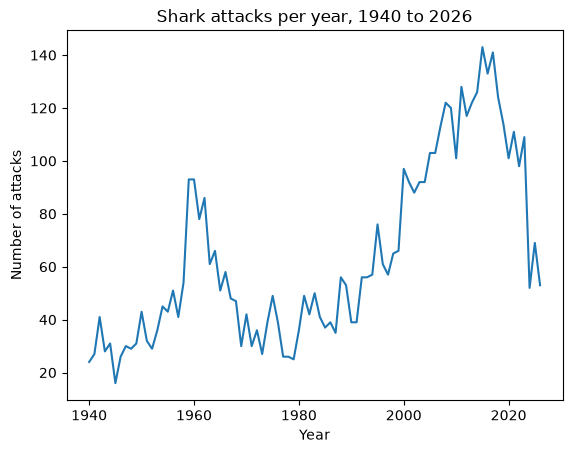

Peak year: 2015 with 143 attacks


In [550]:
import matplotlib.pyplot as plt

df_cleaned['Year'] = df_cleaned['Year'].astype('Int64') # Remove the decimal place
df_cleaned = df_cleaned.loc[df_cleaned['Year'] >= 1940] # Filter attacks since 1940

print(df_cleaned['Year'].describe(), '\n')
print(df_cleaned['Year'].value_counts().sort_index())
print('NaN sum:', sum(df_cleaned['Year'].isna())) # Now determine how many NaN values Year has

df_counts = df_cleaned['Year'].value_counts().sort_index() # Create variable of value counts by year, sorted
plot = df_counts.plot(kind='line') # Plot a line chart
plot.set_title('Shark attacks per year, 1940 to 2026')
plot.set_xlabel('Year')
plot.set_ylabel('Number of attacks')
plt.show()

print('Peak year:', df_counts.idxmax(), 'with', df_counts.max(), 'attacks')



Attacks in general have increased over time, although not linearly. I plotted a quick line chart to visualize the relationship between year and the number of shark attacks. Attacks per year peaked locally around 1960 and then again in 2015 with 143 attacks. Also, since 2026 represents are partial year, it can't be compared yet with other years. 

#### Q2.5, Q2.6 and Q2.7: Cleaning `Age` and plotting the distribution

In [551]:
print(df_cleaned['Age'].dtype) # Initial Age description
print(df_cleaned['Age'].describe(), '\n')
print(df_cleaned['Age'].unique())
print(df_cleaned['Age'].value_counts(), '\n')

object
count     3804
unique     239
top         16
freq        80
Name: Age, dtype: int64 

['?' '43' '27' '71' '21' '69' '31' '13' '12' '17' '35' "20's" '19' '11'
 '20' '38' '39' '16' '22' '30+' "50's" '55' '26' '56' '24' '25' '61' '40'
 '14' '50+' '54' '48' '57' '8' '63' '9' '7' '85' '18' '66' '37' '42' '45'
 '30' '60' '40+' '29' 35 58 29 24 20 55 17 12 37 36 23 40 28 69 48 '60+'
 57 45 61 27 38 16 68 33 30 15 41 14 43 26 'Middle age' 18 21 49 25 46 19
 65 64 nan '46' '32' '10' '64' '62' '15' '52' '44' '47' '59' '50' '34'
 '30s' '20/30' '65' '20s' '77' '49' '!2' '73' '50s' '58' '67' '6' '41'
 '53' '68' '51' 39 51 10 13 60 '40s' 62 'teen' 8 22 32 56 'Teen' 42 50 'M'
 9 31 11 34 '!6' '!!' 47 7 71 59 53 54 75 '45 and 15' 73 52 70 4 63 44
 '28 & 22' '22, 57, 31' '60s' 67 74 '9 & 60' 'a minor' 6 3 82 '40?' 66 72
 '23' '36' '70' '18 months' '28' '33' '74' '3' '28 & 26' '5' '86'
 '18 or 20' '12 or 13' '46 & 34' '28, 23 & 30' 'Teens' 77 '36 & 26'
 '8 or 10' 84 '\xa0 ' ' ' '30 or 36' '6½' '2

In [552]:
print('NaN sum:', sum(df_cleaned['Age'].isna())) # Determine how many NaN values Age has

print('Occurances of "or":', df_cleaned['Age'].str.count('or').sum()) # Number of times "or" is in a value in Age
print('Occurances of "and":', df_cleaned['Age'].str.count('and').sum()) 
print('Occurances of "&":', df_cleaned['Age'].str.count('&').sum()) 
print('Occurances of "months":', df_cleaned['Age'].str.count('months').sum()) 

# Count every value that fails to convert
as_num = pd.to_numeric(df_cleaned['Age'], errors='coerce')
messy = df_cleaned['Age'][as_num.isna() & df_cleaned['Age'].notna()]
print('Non-numeric, non-null values:', len(messy), '\n')
print(messy.astype(str).value_counts().head(15))

NaN sum: 1777
Occurances of "or": 11.0
Occurances of "and": 1.0
Occurances of "&": 22.0
Occurances of "months": 3.0
Non-numeric, non-null values: 159 

Age
?          36
30s        12
20s        10
Teen        9
50s         5
40s         5
teen        4
60s         3
20's        2
30+         2
8 or 10     2
            2
50's        1
50+         1
40+         1
Name: count, dtype: int64


I need to convert `Age` to a numeric variable, but first I have to decide what to do with the messy values. There are many problems here. Some values have multiple ages, some just have age descriptions, and others are completely unknown. Searching for "or", "and", "&" and "months" only finds a fraction of the problem (47 occurances), so I counted every value that fails to convert to a number instead. There are 159 non-numeric non-null values. Since I would have to estimate ages to recover these values, and they only represent 159 out of 1777 total NaN values, I will coerce every messy value to be NaN. 

Missing age values: 1936 of 5581 rows (34.7%) 

count    3645.000000
mean       28.638409
std        14.843747
min         1.000000
25%        17.000000
50%        25.000000
75%        38.000000
max        87.000000
Name: Age, dtype: float64 

Age
17.0    151
20.0    141
15.0    141
19.0    137
18.0    137
       ... 
84.0      1
87.0      1
1.0       1
81.0      1
78.0      1
Name: count, Length: 82, dtype: int64 



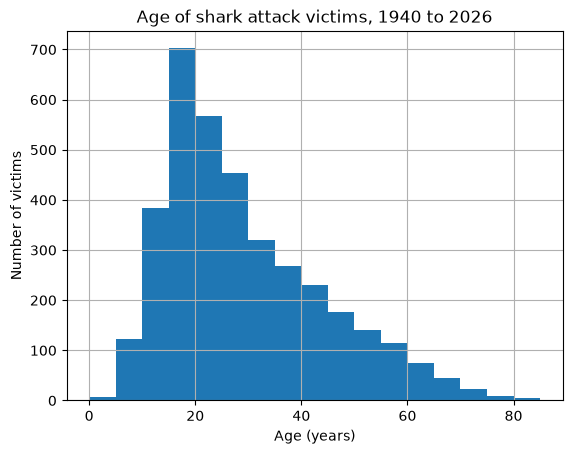

In [553]:
df_cleaned['Age'] = pd.to_numeric(df_cleaned['Age'], errors='coerce') # Convert the object type to numeric, make all messy data NaN
df_cleaned['Age_NaN'] = df_cleaned['Age'].isnull() # Preserve countable record of null values

n_missing_age = sum(df_cleaned['Age_NaN']) # Sum all missing values
print('Missing age values:', n_missing_age, 'of', len(df_cleaned), 'rows',
      '(' + str(round(n_missing_age / len(df_cleaned) * 100, 1)) + '%)', '\n')

print(df_cleaned['Age'].describe(), '\n')
print(df_cleaned['Age'].value_counts(), '\n')

plot = df_cleaned['Age'].hist(bins = range(0, 90, 5)) # Create histogram
plot.set_title('Age of shark attack victims, 1940 to 2026')
plot.set_xlabel('Age (years)')
plot.set_ylabel('Number of victims')
plt.show()

34.7% of age values are missing (1,936 of 5,581). 1,777 were already blank and 159 were
messy strings I coerced. Losing a third of the records is a real limitation, but now that the `Age` variable is clean, you can see the distribution on the histogram. 

The distribution is right-skewed, with a median of 25 and a range spanning from 1 to 87. The most frequent age to be attacked by a shark is 17, with the number of victims declining as ages increase.

#### Q2.8: What proportion of victims are male?

In [554]:
print(df_cleaned['Sex'].describe(), '\n') # Initial Sex description
print(df_cleaned['Sex'].unique(), '\n')
print(df_cleaned['Sex'].value_counts(), '\n')
print('NaN sum:', sum(df_cleaned['Sex'].isna())) # Determine how many NaN values Sex has

count     5130
unique      10
top          M
freq      4384
Name: Sex, dtype: object 

<StringArray>
['F', 'M', 'M ', 'M F', '?', 'F ', nan, ' M', 'm', 'lli', 'M x 2']
Length: 11, dtype: str 

Sex
M        4384
F         730
M           7
?           2
F           2
M F         1
 M          1
m           1
lli         1
M x 2       1
Name: count, dtype: int64 

NaN sum: 451


I will drop the rows with multiple victims, such as "M F" and "M x 2", to be consist with how I treated `Age` (made them NaN). I will also make "?", and "lli" values NaN. I will clean the other male values to have no spaces before/after and follow the same capitalization as "M".

In [555]:
df_cleaned['Sex'] = df_cleaned['Sex'].replace(['M F', 'lli', 'M x 2', '?'], np.nan) # Replace messy values with NaN
df_cleaned['Sex'] = df_cleaned['Sex'].str.strip() # Remove extra spaces around Sex values
df_cleaned['Sex'] = df_cleaned['Sex'].str.upper() # Make Sex values uppercase

print(df_cleaned['Sex'].value_counts(), '\n')

n_total = len(df_cleaned) # Count total values
n_known = df_cleaned['Sex'].notna().sum() # Count number of non-null values
n_male = (df_cleaned['Sex'] == 'M').sum() # Count number of male values

print('Total records since 1940:', n_total)
print('Number of missing values:', round((n_total - n_known)/n_total*100, 2), "%")
print('Proportion of male victims:', round(df_cleaned['Sex'].value_counts(normalize=True)['M']*100,2), "%") # Calculate the relative frequency of the "M" value 


Sex
M    4393
F     732
Name: count, dtype: int64 

Total records since 1940: 5581
Number of missing values: 8.17 %
Proportion of male victims: 85.72 %


85.72% of victims with a recorded sex are male (4,393 of 5,125). 8.17% of records have no sex recorded.

#### Q2.9, Q2.10 and Q2.11: Cleaning `Type` and the unprovoked proportion

In [556]:
print(df_cleaned['Type'].describe(), '\n') # Initial Type description
print(df_cleaned['Type'].unique(), '\n')
print(df_cleaned['Type'].value_counts(), '\n')
print('NaN sum:', sum(df_cleaned['Type'].isna())) # Determine how many NaN values Type has

count           5567
unique            14
top       Unprovoked
freq            4161
Name: Type, dtype: object 

<StringArray>
[         'Unprovoked',            'Provoked',        'Questionable',
          'UNprovoked',          'unprovoked',           ' Provoked',
          'Watercraft',        'Sea Disaster',                   nan,
                   '?',         'Unconfirmed',          'Unverified',
             'Invalid', 'Under investigation',                'Boat']
Length: 15, dtype: str 

Type
Unprovoked             4161
Provoked                526
Invalid                 402
Watercraft              280
Sea Disaster            156
Questionable             27
Boat                      7
 Provoked                 2
UNprovoked                1
unprovoked                1
?                         1
Unconfirmed               1
Unverified                1
Under investigation       1
Name: count, dtype: int64 

NaN sum: 14


In order to make all the values fall into Provoked, Unprovoked, and Unknown, I will first remove the extra spaces and capitalize the values. Then I will impute all values other than Provoked and Unprovoked to be Unknown. I didn't make a separate impute variable since df already has been copied via `df_cleaned`.

In [557]:
df_cleaned['Type'] = df_cleaned['Type'].str.strip() # Remove extra spaces
df_cleaned['Type'] = df_cleaned['Type'].str.capitalize() # Make values capitalized

print(df_cleaned['Type'].value_counts(), '\n')

impute_value = 'Unknown'
df_cleaned['Type'] = np.where(df_cleaned['Type'].isin(['Provoked','Unprovoked']), df_cleaned['Type'],impute_value) # For any value that isn't "Provoked" or "Unprovoked", fill in "Unknown"
print(df_cleaned['Type'].value_counts(), '\n')

print('Total records since 1940:', len(df_cleaned['Type']))
print('Proportion of unprovoked attacks:', round(df_cleaned['Type'].value_counts(normalize = True)['Unprovoked']*100,2), "%")



Type
Unprovoked             4163
Provoked                528
Invalid                 402
Watercraft              280
Sea disaster            156
Questionable             27
Boat                      7
?                         1
Unconfirmed               1
Unverified                1
Under investigation       1
Name: count, dtype: int64 

Type
Unprovoked    4163
Unknown        890
Provoked       528
Name: count, dtype: int64 

Total records since 1940: 5581
Proportion of unprovoked attacks: 74.59 %


74.59% of all attacks since 1940 are unprovoked (4,163 of 5,581). This figure uses total number of records as the denominator. I used total count in the denominator for this proportion since the prompt is explicit about breaking the variable into three categories.

### *Reflection on AI assistance
In your own words without generative AI.

The main improvement was cleaning up my presentation of data. For example, AI helped me present the cross-tabulation in a more viewer-friendly way by showing proportions rather than raw numbers. I also added subheadings and labels on my charts per AI's recommendation. It also helped me find an inconsistency in one of my markdown comments. The main limitaiton was that AI would try to complicate some of the solutions. For example, with the proportion questions, it wanted me to use two bounds (one with unknown values included and one without) and provide two different proportions as my answer. I used manual math and checked between my previous work and AI's improved solution to verify the results. I also was clear to make sure AI didn't override any of my work other than the suggestions that I approved. By asking for a list of the top 10 improvements, it was easier to organize AI's thoughts. Next time, I don't think I will ask for 10 items, because it felt like some of the feedback weren't important to my overall solution, but AI just provided it to get to the 10 items.